# Facebook Ad Campaign Performance: Where Should the Budget Go?

**Questions**
1. Which of the company's three ad campaigns turns spend into customers most efficiently?
2. Which audiences (age, gender, interest) are cheapest to convert?
3. Does spending more on an ad keep paying off, or do returns fall?
4. How could the same budget buy more conversions?

**Data:** 1,143 Facebook ads from three campaigns run by an anonymous company, with each ad's audience (age group, gender, interest), impressions, clicks, spend and conversions. Published on Kaggle as *Sales Conversion Optimization*.

**Tools:** Python, pandas, matplotlib, statsmodels.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

DEEP, DARK, MID, LIGHT, SOFT, PLUM = "#880E4F", "#D81B60", "#F48FB1", "#F8BBD0", "#E8A0BF", "#AD1457"   # pink palette
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

ads = pd.read_csv("data/facebook_ad_campaigns.csv")
ads = ads.rename(columns={"xyz_campaign_id": "campaign", "Impressions": "impressions", "Clicks": "clicks", "Spent": "spend",
                          "Total_Conversion": "inquiries", "Approved_Conversion": "purchases"})
ads["campaign"] = ads.campaign.map({916: "Campaign A", 936: "Campaign B", 1178: "Campaign C"})
print(ads.shape, "| missing values:", int(ads.isna().sum().sum()), "| duplicate ads:", int(ads.ad_id.duplicated().sum()))
ads.head()

(1143, 11) | missing values: 0 | duplicate ads: 0


,ad_id,campaign,fb_campaign_id,age,gender,interest,impressions,clicks,spend,inquiries,purchases
0,708746,Campaign A,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,Campaign A,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,Campaign A,103920,30-34,M,20,693,0,0.00,1,0
3,708815,Campaign A,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,Campaign A,103928,30-34,M,28,4133,1,1.29,1,1


Each row is one ad. The company's own campaign IDs (916, 936, 1178) are relabelled A, B and C. The dataset documentation describes two kinds of conversion:

- **Inquiries** (`Total_Conversion`): people who enquired about the product after seeing the ad
- **Purchases** (`Approved_Conversion`): people who went on to buy

Purchases are what the business is paying for, so the main efficiency measure in this analysis is **cost per purchase** (spend divided by purchases), often called cost per acquisition or CPA. The data has no revenue figures, so return on ad spend (ROAS) cannot be calculated.

## 2. Data checks

In [2]:
zero_spend = ads.spend == 0
print(f"ads with zero spend: {zero_spend.sum()} ({zero_spend.mean():.0%})")
print(f"  ... of which had at least one inquiry: {(zero_spend & (ads.inquiries > 0)).sum()}")
print(f"  ... and at least one purchase:        {(zero_spend & (ads.purchases > 0)).sum()}")
print(f"ads where zero spend and zero clicks go together: {((ads.spend == 0) == (ads.clicks == 0)).mean():.0%}")
print(f"ads with more inquiries than clicks: {(ads.inquiries > ads.clicks).sum()}")
print(f"ads with more purchases than inquiries: {(ads.purchases > ads.inquiries).sum()}")
print(f"\nzero-spend ads' share of all purchases: {ads.loc[zero_spend, 'purchases'].sum() / ads.purchases.sum():.1%}")

ads with zero spend: 207 (18%)
  ... of which had at least one inquiry: 204
  ... and at least one purchase:        71
ads where zero spend and zero clicks go together: 100%
ads with more inquiries than clicks: 218
ads with more purchases than inquiries: 0

zero-spend ads' share of all purchases: 7.0%


Two things in the data need explaining before any analysis:

- **207 ads (18%) spent nothing and got no clicks, yet 204 of them recorded inquiries and 71 recorded purchases.** These ads were most likely never delivered as paid ads, and the conversions credited to them came from people who reached the product another way. They account for 7% of purchases. I keep them in the totals, because removing them would make the campaigns look worse than the company's own numbers, but they are excluded from the spend-versus-results analysis in Section 7, where an ad with no spend tells us nothing.
- **218 ads have more inquiries than clicks.** That is only possible if Facebook credits conversions to people who *saw* an ad without clicking it ("view-through" conversions). So these conversion numbers measure what Facebook attributes to the ads, which tends to be generous, not what the ads provably caused.

There are no missing values, no duplicate ads, and no ad has more purchases than inquiries, so the data is otherwise consistent.

## 3. The marketing funnel, overall

In [3]:
def funnel(g):
    s = g[["impressions", "clicks", "spend", "inquiries", "purchases"]].sum()
    return pd.Series({
        "ads": len(g), "impressions": s.impressions, "clicks": s.clicks, "spend": s.spend,
        "inquiries": s.inquiries, "purchases": s.purchases,
        "ctr_pct": 100 * s.clicks / s.impressions,
        "cpc": s.spend / s.clicks,
        "cpm": 1000 * s.spend / s.impressions,
        "cost_per_inquiry": s.spend / s.inquiries,
        "cost_per_purchase": s.spend / s.purchases,
        "inquiry_to_purchase_pct": 100 * s.purchases / s.inquiries,
        "spend_share_pct": 100 * s.spend / ads.spend.sum(),
        "purchase_share_pct": 100 * s.purchases / ads.purchases.sum(),
    })

overall = funnel(ads)
print(overall.round(3).to_string())

ads                        1.143000e+03
impressions                2.134348e+08
clicks                     3.816500e+04
spend                      5.870523e+04
inquiries                  3.264000e+03
purchases                  1.079000e+03
ctr_pct                    1.800000e-02
cpc                        1.538000e+00
cpm                        2.750000e-01
cost_per_inquiry           1.798600e+01
cost_per_purchase          5.440700e+01
inquiry_to_purchase_pct    3.305800e+01
spend_share_pct            1.000000e+02
purchase_share_pct         1.000000e+02


Across all 1,143 ads, the company spent **$58,705** and got **1,079 purchases**, an average of **$54 per purchase**. (The dataset does not state its currency; I use $ throughout.)

The funnel narrows sharply at each step: 213 million impressions led to 38,165 clicks (a click-through rate of 0.018%), 3,264 inquiries and 1,079 purchases. About one inquiry in three became a purchase.

## 4. Comparing the three campaigns

In [4]:
camp = ads.groupby("campaign").apply(funnel, include_groups=False)
print(camp.round(2).T.to_string())

campaign                 Campaign A  Campaign B    Campaign C
ads                           54.00      464.00  6.250000e+02
impressions               482925.00  8128187.00  2.048237e+08
clicks                       113.00     1984.00  3.606800e+04
spend                        149.71     2893.37  5.566215e+04
inquiries                     58.00      537.00  2.669000e+03
purchases                     24.00      183.00  8.720000e+02
ctr_pct                        0.02        0.02  2.000000e-02
cpc                            1.32        1.46  1.540000e+00
cpm                            0.31        0.36  2.700000e-01
cost_per_inquiry               2.58        5.39  2.086000e+01
cost_per_purchase              6.24       15.81  6.383000e+01
inquiry_to_purchase_pct       41.38       34.08  3.267000e+01
spend_share_pct                0.26        4.93  9.482000e+01
purchase_share_pct             2.22       16.96  8.082000e+01


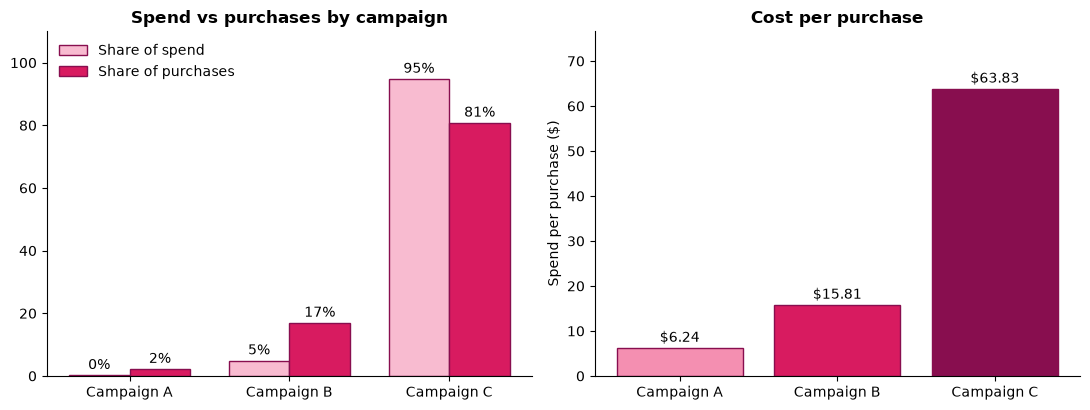

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(camp)); w = 0.38
b1 = axes[0].bar(x - w / 2, camp.spend_share_pct, w, color=LIGHT, edgecolor=DEEP, label="Share of spend")
b2 = axes[0].bar(x + w / 2, camp.purchase_share_pct, w, color=DARK, edgecolor=DEEP, label="Share of purchases")
axes[0].bar_label(b1, fmt="%.0f%%", padding=2); axes[0].bar_label(b2, fmt="%.0f%%", padding=2)
axes[0].set_xticks(x, camp.index); axes[0].set_ylim(0, 110); axes[0].set_title("Spend vs purchases by campaign"); axes[0].legend(frameon=False, loc="upper left")
b3 = axes[1].bar(camp.index, camp.cost_per_purchase, color=[MID, DARK, DEEP], edgecolor=DEEP)
axes[1].bar_label(b3, fmt="$%.2f", padding=2)
axes[1].set_title("Cost per purchase"); axes[1].set_ylabel("Spend per purchase ($)"); axes[1].set_ylim(0, camp.cost_per_purchase.max() * 1.2)
plt.tight_layout(); plt.savefig("images/campaign_comparison.svg"); plt.show()

The campaigns differ enormously in cost:

| Campaign | Share of spend | Share of purchases | Cost per purchase |
|---|---|---|---|
| A | 0.3% | 2% | $6.24 |
| B | 5% | 17% | $15.81 |
| C | **95%** | **81%** | **$63.83** |

Campaign C takes 95% of the budget but delivers 81% of purchases, and each purchase costs about four times as much as in Campaign B and ten times as much as in Campaign A.

This does not simply mean Campaign C is badly run. It is about 20 times larger than B, and Section 7 shows that cost per purchase rises as spend rises, so part of the gap is the price of scale. Campaigns A and B may look cheap partly because they were small. The clear conclusion is that Campaign C is where the money is and where efficiency matters most, and the rest of the analysis focuses on it.

## 5. Which audiences are cheapest to convert?

Campaign C accounts for most of the spend and is the only campaign large enough to compare audiences within. Comparing audiences across all three campaigns at once would mix up two things: who the audience is and which campaign the ad belonged to. So this section looks at Campaign C on its own.

In [6]:
c = ads[ads.campaign == "Campaign C"]
by_age = c.groupby("age").apply(funnel, include_groups=False)[["ads", "spend", "purchases", "ctr_pct", "cost_per_purchase", "inquiry_to_purchase_pct"]]
by_gender = c.groupby("gender").apply(funnel, include_groups=False)[["ads", "spend", "purchases", "ctr_pct", "cost_per_purchase", "inquiry_to_purchase_pct"]]
print("By age group (Campaign C):"); print(by_age.round(2).to_string())
print("\nBy gender (Campaign C):"); print(by_gender.round(2).to_string())

By age group (Campaign C):
         ads     spend  purchases  ctr_pct  cost_per_purchase  inquiry_to_purchase_pct
age                                                                                   
30-34  201.0  14785.63      395.0     0.01              37.43                    33.67
35-39  147.0  10705.36      167.0     0.02              64.10                    32.30
40-44  129.0  11122.52      141.0     0.02              78.88                    32.56
45-49  148.0  19048.64      169.0     0.02             112.71                    30.95

By gender (Campaign C):
          ads     spend  purchases  ctr_pct  cost_per_purchase  inquiry_to_purchase_pct
gender                                                                                 
F       276.0  32052.41      391.0     0.02              81.98                    29.58
M       349.0  23609.74      481.0     0.01              49.08                    35.71


A difference in cost per purchase could just be noise, so I bootstrap it: resample Campaign C's ads 5,000 times and recompute cost per purchase for each group.

       cost_per_purchase  ci_low  ci_high
30-34              37.43   32.36    43.43
35-39              64.10   54.34    75.85
40-44              78.88   63.85    99.52
45-49             112.71   93.19   138.25

   cost_per_purchase  ci_low  ci_high
F              81.98   71.79    95.51
M              49.08   42.90    56.37


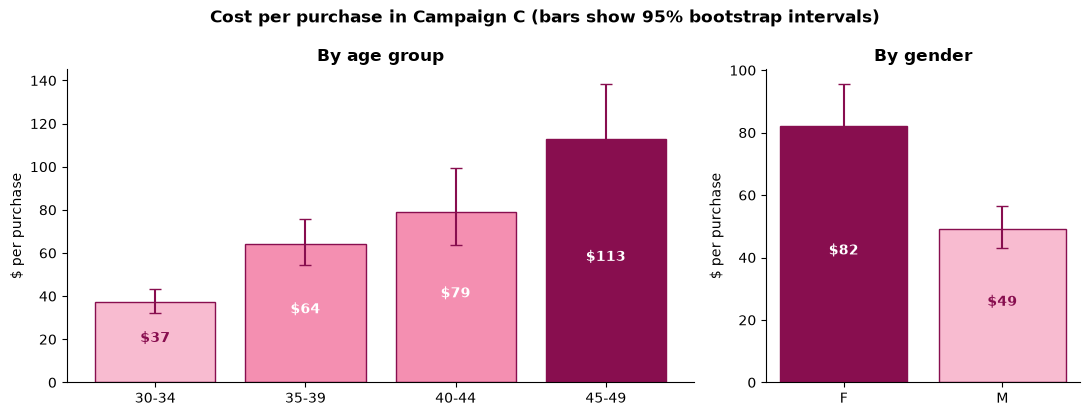

In [7]:
rng = np.random.default_rng(42)
def boot_cpa(frame, key, B=5000):
    out = {}
    for g, sub in frame.groupby(key):
        sp, pu = sub.spend.to_numpy(), sub.purchases.to_numpy()
        idx = rng.integers(0, len(sub), (B, len(sub)))
        vals = sp[idx].sum(1) / np.maximum(pu[idx].sum(1), 1)
        out[g] = (sp.sum() / pu.sum(), *np.percentile(vals, [2.5, 97.5]))
    return pd.DataFrame(out, index=["cost_per_purchase", "ci_low", "ci_high"]).T

age_ci = boot_cpa(c, "age"); gender_ci = boot_cpa(c, "gender")
print(age_ci.round(2).to_string()); print(); print(gender_ci.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [2, 1]})
for ax, ci, title in [(axes[0], age_ci, "By age group"), (axes[1], gender_ci, "By gender")]:
    colors = [DEEP if v == ci.cost_per_purchase.max() else (LIGHT if v == ci.cost_per_purchase.min() else MID) for v in ci.cost_per_purchase]
    ax.bar(ci.index, ci.cost_per_purchase, color=colors, edgecolor=DEEP,
           yerr=[ci.cost_per_purchase - ci.ci_low, ci.ci_high - ci.cost_per_purchase], capsize=4, ecolor=DEEP)
    for i, v in enumerate(ci.cost_per_purchase): ax.text(i, v / 2, f"${v:.0f}", ha="center", color="white" if v > 60 else DEEP, fontweight="bold")
    ax.set_title(title); ax.set_ylabel("$ per purchase")
fig.suptitle("Cost per purchase in Campaign C (bars show 95% bootstrap intervals)", fontweight="bold", color="black")
plt.tight_layout(); plt.savefig("images/cost_per_purchase_by_audience.svg"); plt.show()

Within Campaign C, age is the strongest pattern in the data:

- **30 to 34 year olds cost $37 per purchase**, against **$113 for 45 to 49 year olds**: three times as much. Cost rises steadily with every age group, and the bootstrap intervals for the youngest and oldest groups ($32 to $43 and $93 to $138) are far apart, so this is not noise.
- **Men cost $49 per purchase and women $82.** The intervals do not overlap here either. Women's ads had a slightly higher click-through rate but a lower share of inquiries turning into purchases (30% vs 36%).

The budget is not following these numbers. The most expensive age group (45 to 49) received the most money of any age group ($19,049), more than the cheapest (30 to 34, $14,786). Women received 58% of Campaign C's spend despite costing 67% more per purchase.

## 6. Interest groups

Each ad targeted one of 40 interest categories (coded as numbers in the data, so the topics themselves are unknown). I compare the interest groups in Campaign C that had at least $500 of spend, so each figure rests on a meaningful number of purchases.

interest groups with $500+ spend: 27 of 40, covering 91% of Campaign C spend
           ads    spend  purchases  ctr_pct  cost_per_purchase
interest                                                      
101        7.0   757.69       25.0     0.02              30.31
21        22.0   794.62       21.0     0.02              37.84
7         14.0   634.41       16.0     0.02              39.65
29        35.0  4767.48      110.0     0.02              43.34
107        8.0   923.18       20.0     0.01              46.16
20        24.0  1910.23       39.0     0.02              48.98
15        20.0  2514.30       50.0     0.01              50.29
110        8.0   521.35        9.0     0.01              57.93
24        16.0   658.26       11.0     0.02              59.84
100        6.0   574.31        9.0     0.02              63.81
19        23.0  1921.21       30.0     0.02              64.04
30        16.0   605.07        9.0     0.02              67.23
16        38.0  6826.51      101.0     0.

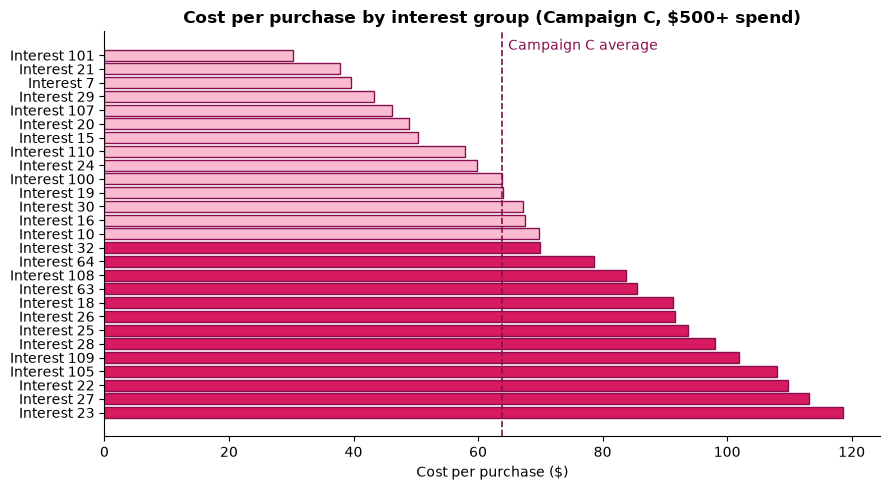

In [8]:
by_int = c.groupby("interest").apply(funnel, include_groups=False)
big = by_int[by_int.spend >= 500].sort_values("cost_per_purchase")
print(f"interest groups with $500+ spend: {len(big)} of {len(by_int)}, covering {big.spend.sum() / c.spend.sum():.0%} of Campaign C spend")
print(big[["ads", "spend", "purchases", "ctr_pct", "cost_per_purchase"]].round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
order = big.sort_values("cost_per_purchase", ascending=False)
med = big.cost_per_purchase.median()
ax.barh([f"Interest {i}" for i in order.index], order.cost_per_purchase,
        color=[LIGHT if v <= med else DARK for v in order.cost_per_purchase], edgecolor=DEEP)
ax.axvline(c.spend.sum() / c.purchases.sum(), color=DEEP, ls="--", lw=1.2)
ax.text(c.spend.sum() / c.purchases.sum() + 1, len(order) - 0.6, "Campaign C average", color=DEEP)
ax.set_xlabel("Cost per purchase ($)"); ax.set_title("Cost per purchase by interest group (Campaign C, $500+ spend)")
plt.tight_layout(); plt.savefig("images/cost_per_purchase_by_interest.svg"); plt.show()

Among the 27 interest groups with at least $500 of spend (91% of Campaign C's budget), cost per purchase ranges from **$30 (interest 101) to $119 (interest 23)**, a fourfold difference within the same campaign.

The most useful finding is where the money sits. **Interest 29** is both large ($4,767 of spend) and efficient ($43 per purchase). **Interest 27** received a similar budget ($4,863) at more than twice the cost ($113 per purchase). Interest 16, the biggest single group ($6,827), is about average at $68.

Some groups rest on only five to ten purchases, so their exact figures are uncertain. The larger groups, such as 29, 16, 10 and 27, are the ones to act on.

## 7. Does spending more keep paying off?

If every extra dollar bought the same number of purchases, doubling an ad's spend would double its purchases. I test this with a log-log regression of purchases on spend for Campaign C ads that spent money. The slope is the elasticity: a slope of 1 means purchases grow in proportion to spend, and a slope below 1 means each extra dollar buys less.

elasticity of purchases with respect to spend: 0.267 (95% CI 0.229 to 0.305), n = 613
               ads  median_spend     spend  purchases  cost_per_purchase
spend_band                                                              
Lowest 20%   123.0          8.22   1010.60       61.0              16.57
20-40%       122.0         25.61   3228.09       96.0              33.63
40-60%       123.0         50.50   6291.52      114.0              55.19
60-80%       122.0        104.57  12753.70      164.0              77.77
Highest 20%  123.0        243.77  32378.24      434.0              74.60


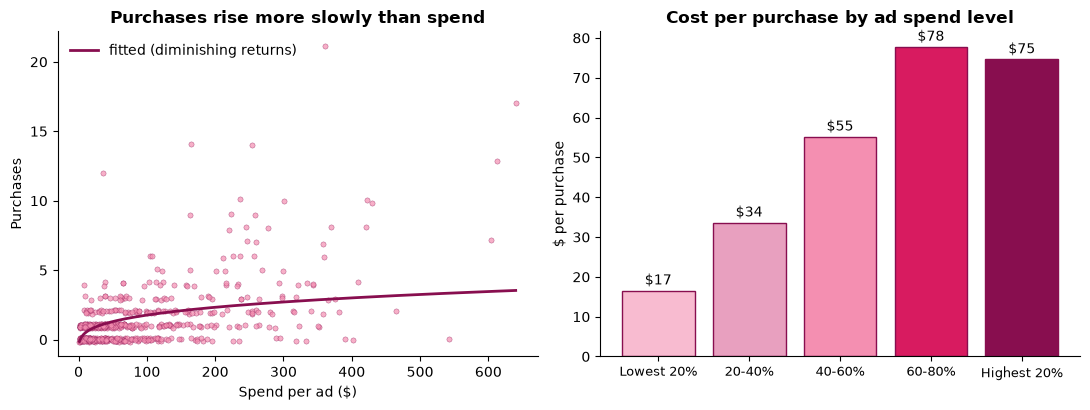

In [9]:
paid = c[c.spend > 0].copy()
paid["log_spend"] = np.log(paid.spend)
paid["log_purchases"] = np.log1p(paid.purchases)
paid["log_impr"] = np.log(paid.impressions)
m = smf.ols("log_purchases ~ log_spend + C(age) + C(gender)", data=paid).fit(cov_type="HC1")
lo, hi = m.conf_int().loc["log_spend"]
print(f"elasticity of purchases with respect to spend: {m.params['log_spend']:.3f} (95% CI {lo:.3f} to {hi:.3f}), n = {len(paid)}")

paid["spend_band"] = pd.qcut(paid.spend, 5, labels=["Lowest 20%", "20-40%", "40-60%", "60-80%", "Highest 20%"])
bands = paid.groupby("spend_band", observed=True).apply(funnel, include_groups=False)
bands["median_spend"] = paid.groupby("spend_band", observed=True).spend.median()
print(bands[["ads", "median_spend", "spend", "purchases", "cost_per_purchase"]].round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(paid.spend, paid.purchases + np.random.default_rng(0).uniform(-0.15, 0.15, len(paid)), s=14, color=MID, edgecolor=DEEP, linewidth=0.3, alpha=0.7)
grid = np.linspace(paid.spend.min(), paid.spend.max(), 200)
pred = np.expm1(m.params["Intercept"] + m.params["log_spend"] * np.log(grid))
axes[0].plot(grid, pred, color=DEEP, lw=2, label="fitted (diminishing returns)")
axes[0].set_xlabel("Spend per ad ($)"); axes[0].set_ylabel("Purchases"); axes[0].set_title("Purchases rise more slowly than spend"); axes[0].legend(frameon=False)
bb = axes[1].bar(bands.index.astype(str), bands.cost_per_purchase, color=[LIGHT, SOFT, MID, DARK, DEEP], edgecolor=DEEP)
axes[1].bar_label(bb, fmt="$%.0f", padding=2)
axes[1].set_title("Cost per purchase by ad spend level"); axes[1].set_ylabel("$ per purchase"); axes[1].tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.savefig("images/diminishing_returns.svg"); plt.show()

**Spending more on an ad buys fewer purchases per dollar.** The estimated elasticity is **0.27** (95% CI 0.23 to 0.31): doubling an ad's spend is associated with only about 20% more purchases, not twice as many. This holds after allowing for the audience's age and gender.

The cost per purchase by spend level tells the same story. Ads in the lowest-spending fifth bought purchases at **$17** each, and ads in the top two fifths at **$75 to $78**. The curve flattens at the top rather than rising further, so the steepest increase in cost comes in the middle of the range.

Two cautions. The regression uses the log of purchases plus one, because many ads had none, which makes the elasticity approximate. And this is a comparison between ads, not an experiment: ads that were given larger budgets may also have targeted harder audiences. Even so, the pattern is strong and consistent, and it means that the cheapest way to get more purchases is usually to spread money across more efficient ads rather than push more into the biggest ones.

## 8. A budget reallocation scenario

What if Campaign C's budget were moved from its most expensive interest groups to its cheapest ones? This is a rough scenario, not a forecast: it assumes the cheaper groups keep their current cost per purchase when they get more money, and Section 7 shows costs rise with spend. To allow for that, I also run a version where the extra money buys purchases at a cost 50% higher than the group's current rate.

In [10]:
cheap = big[big.cost_per_purchase <= med]; costly = big[big.cost_per_purchase > med]
move = 0.5 * costly.spend.sum()                                     # move half of the expensive groups' budget
lost = 0.5 * costly.purchases.sum()                                 # purchases lost by cutting it
cheap_cpa = cheap.spend.sum() / cheap.purchases.sum()
gained_optimistic = move / cheap_cpa
gained_cautious = move / (cheap_cpa * 1.5)
print(f"budget moved: ${move:,.0f} ({move / c.spend.sum():.0%} of Campaign C spend)")
print(f"cost per purchase, cheaper half of interest groups: ${cheap_cpa:.2f}; more expensive half: ${costly.spend.sum() / costly.purchases.sum():.2f}")
print(f"purchases lost from the expensive groups: {lost:.0f}")
print(f"purchases gained if cost stays the same:   {gained_optimistic:.0f}  -> net {gained_optimistic - lost:+.0f}")
print(f"purchases gained if cost rises 50%:         {gained_cautious:.0f}  -> net {gained_cautious - lost:+.0f}")
print(f"net change as a share of Campaign C purchases: {(gained_optimistic - lost) / c.purchases.sum():+.1%} to {(gained_cautious - lost) / c.purchases.sum():+.1%}")

budget moved: $11,372 (20% of Campaign C spend)
cost per purchase, cheaper half of interest groups: $54.35; more expensive half: $93.98
purchases lost from the expensive groups: 121
purchases gained if cost stays the same:   209  -> net +88
purchases gained if cost rises 50%:         139  -> net +18
net change as a share of Campaign C purchases: +10.1% to +2.1%


Moving half of the budget from the more expensive interest groups to the cheaper ones would shift about **$11,400 (20% of Campaign C)**:

- If the cheaper groups kept their current cost of $54 per purchase, the move would add about **88 purchases (+10%)** for the same total spend.
- If the extra money cost 50% more per purchase, which Section 7 suggests is realistic, the gain would be about **18 purchases (+2%)**.

The honest range is somewhere between a small and a moderate improvement. That is still worth having for no extra spend, and the way to find out the true figure is to test it: shift part of the budget for a few weeks and compare against the current split, as an A/B test.

## 9. Conclusions

**Findings**

1. **Campaign C takes 95% of the budget but delivers 81% of purchases,** at $64 per purchase, against $16 for Campaign B and $6 for Campaign A. Part of that gap is the cost of running at a much larger scale.
2. **Younger audiences are far cheaper to convert.** In Campaign C, 30 to 34 year olds cost $37 per purchase and 45 to 49 year olds $113, yet the older group received more budget.
3. **Men converted at $49 per purchase and women at $82,** while women received 58% of the spend.
4. **Interest groups differ fourfold** ($30 to $119 per purchase), and similar budgets went to efficient and inefficient groups.
5. **Returns diminish with spend.** Doubling an ad's spend is associated with only about 20% more purchases.

**Recommendations**

- **Rebalance Campaign C toward 30 to 39 year olds and toward the cheaper interest groups,** such as 29, 20 and 15, and away from groups like 27 and 28. Expect a gain of roughly 2% to 10% more purchases for the same spend.
- **Cap the budget of individual ads** and spread it across more ads, since each extra dollar on a large ad buys less.
- **Test before committing.** Run the reallocation on part of the budget as an experiment for a few weeks, because these figures come from past data, not a controlled test.
- **Track revenue per purchase.** With it, the company could calculate return on ad spend and check whether older or female customers spend more, which would justify their higher acquisition cost.

**Limitations**

- **No revenue data,** so return on ad spend cannot be calculated. A segment that costs more per purchase could still be worth it if those customers spend more.
- **Conversions are Facebook's attributions,** including view-through conversions and conversions credited to ads that never ran, so they likely overstate what the ads caused.
- **Observational data.** Audience and budget were chosen by the company, not assigned at random, so differences between groups may partly reflect how the ads were set up.
- **Interest categories are anonymous numbers,** so they cannot be turned into named audiences without the company's codebook.
- **Unknown currency and dates.** The dataset does not say when the ads ran or in which currency.